# RMDS - Hackathon (Group G)

## Name - Sai Mahesh Battula

## Student ID - 24069723


## The given dataset is Dataset-B.

### 1. IMPORT REQUIRED LIBRARIES.

In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.3f}'.format)

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


Why are we importing these?
- Pandas: Loading and manipulating datasets.
- NumPy: Numerical operations.
- Matplotlib and Seaborn: Data visualisation.
- Scikit-learn: Data preprocessing, machine learning and model evaluation (we'll import specific modules when needed).
- RANDOM_STATE: Ensures reproducibility when we perform random operations.

In [2]:

import os

print("Files available in the current directory:\n")

for file in os.listdir('/content'):
    print(file)


Files available in the current directory:

.config
dataset_B_testing.csv
dataset_B_training.csv
sample_data


### 2. LOAD DATASETS

In [4]:
import glob

training_files = glob.glob('/content/dataset_B_training*')
testing_files = glob.glob('/content/dataset_B_testing*')

if not training_files:
    raise FileNotFoundError("Training dataset not found!")

if not testing_files:
    raise FileNotFoundError("Testing dataset not found!")

print("Training file:", training_files[0])
print("Testing file:", testing_files[0])

# Load CSV files
df_train = pd.read_csv(training_files[0])
df_test = pd.read_csv(testing_files[0])

print("\nDatasets loaded successfully!")

Training file: /content/dataset_B_training.csv
Testing file: /content/dataset_B_testing.csv

Datasets loaded successfully!


### 3. Initial Dataset overview.

In [5]:
print("TRAINING DATASET")
print("=" * 50)

print("Shape:", df_train.shape)
print("\nFirst 5 records:")
display(df_train.head())

print("\nTESTING DATASET")
print("=" * 50)

print("Shape:", df_test.shape)
print("\nFirst 5 records:")
display(df_test.head())

TRAINING DATASET
Shape: (4756, 31)

First 5 records:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_h1n1,child_under_6_months,health_worker,health_insurance,opinion_h1n1_vacc_effective,opinion_h1n1_risk,opinion_h1n1_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.000,2.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,1.000,4.000,4.000,1.000,45 - 54 Years,Some College,White,Female,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.000,1.000,science,0,0
1,2,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,3.000,1.000,2.000,18 - 34 Years,Some College,White,Female,Below Poverty,Not Married,Own,Employed,Non-MSA,0.000,3.000,wholesale,0,0
2,3,2.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,NaN,0.000,0.000,1.000,3.000,4.000,2.000,45 - 54 Years,College Graduate,White,Female,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.000,0.000,education,0,1
3,4,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,2.000,1.000,4.000,18 - 34 Years,College Graduate,White,Female,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.000,0.000,NaN,0,0
4,5,2.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,0.000,NaN,2.000,2.000,1.000,18 - 34 Years,< 12 Years,White,Female,NaN,Not Married,NaN,Unemployed,Non-MSA,3.000,0.000,NaN,0,0



TESTING DATASET
Shape: (4749, 30)

First 5 records:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_h1n1,child_under_6_months,health_worker,health_insurance,opinion_h1n1_vacc_effective,opinion_h1n1_risk,opinion_h1n1_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
0,4757,1.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,4.000,2.000,2.000,65+ Years,12 Years,White,Female,"<= $75,000, Above Poverty",Not Married,Own,Not in Labor Force,"MSA, Principle City",0.000,0.000,NaN,0
1,4758,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,1.000,3.000,4.000,65+ Years,NaN,White,Female,NaN,NaN,NaN,NaN,"MSA, Not Principle City",0.000,0.000,NaN,0
2,4759,1.000,1.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,2.000,1.000,1.000,65+ Years,College Graduate,White,Male,NaN,Married,Own,Not in Labor Force,"MSA, Principle City",1.000,0.000,NaN,0
3,4760,3.000,1.000,0.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,4.000,4.000,2.000,55 - 64 Years,12 Years,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,1.000,0.000,agriculture,1
4,4761,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,3.000,2.000,1.000,35 - 44 Years,Some College,White,Male,"<= $75,000, Above Poverty",Not Married,Own,Employed,Non-MSA,0.000,0.000,wholesale,0


###  4. DATA TYPES AND DATASET INFORMATION.

In [6]:
print("TRAINING DATASET INFORMATION")
print("=" * 50)

df_train.info()

print("\n\nTESTING DATASET INFORMATION")
print("=" * 50)

df_test.info()

TRAINING DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   h1n1_concern                   4741 non-null   float64
 2   h1n1_knowledge                 4734 non-null   float64
 3   behavioral_antiviral_meds      4739 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4752 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4741 non-null   float64
 9   behavioral_touch_face          4736 non-null   float64
 10  doctor_recc_h1n1               4437 non-null   float64
 11  child_under_6_months           4622 non-null   float64
 12  health_worker      

### 5. TARGET VARIABLE DISTRIBUTION

Target variable distribution:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Target variable percentage distribution:
h1n1_vaccine
0   60.597
1   39.403
Name: proportion, dtype: float64


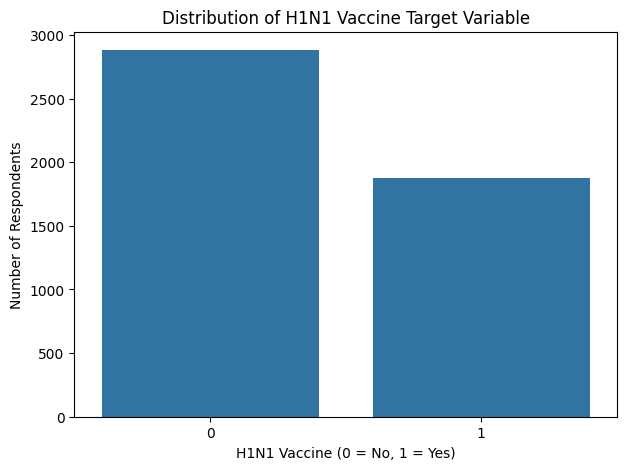

In [7]:
target = 'h1n1_vaccine'

print("Target variable distribution:")
print(df_train[target].value_counts())

print("\nTarget variable percentage distribution:")
print(df_train[target].value_counts(normalize=True) * 100)

# Visualisation
plt.figure(figsize=(7, 5))

sns.countplot(data=df_train, x=target)

plt.title("Distribution of H1N1 Vaccine Target Variable")
plt.xlabel("H1N1 Vaccine (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")

plt.show()

#### The dataset has moderate class imbalance.

### 6. MISSING VALUE ANALYSIS.

In [12]:
# Training dataset
train_missing = pd.DataFrame({
    'Missing_Count': df_train.isnull().sum(),
    'Missing_Percentage': df_train.isnull().mean() * 100
})

# Testing dataset
test_missing = pd.DataFrame({
    'Missing_Count': df_test.isnull().sum(),
    'Missing_Percentage': df_test.isnull().mean() * 100
})

# Display features with missing values
print("TRAINING DATASET - MISSING VALUES")
display(
    train_missing[train_missing['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

print("\nTESTING DATASET - MISSING VALUES")
display(
    test_missing[test_missing['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)


TRAINING DATASET - MISSING VALUES


,Missing_Count,Missing_Percentage
employment_sector,2364,49.706
health_insurance,1925,40.475
income_poverty,712,14.971
doctor_recc_h1n1,319,6.707
rent_or_own,315,6.623
employment_status,235,4.941
marital_status,226,4.752
education,224,4.710
child_under_6_months,134,2.817
health_worker,131,2.754



TESTING DATASET - MISSING VALUES


,Missing_Count,Missing_Percentage
employment_sector,2405,50.642
health_insurance,1982,41.735
income_poverty,797,16.782
rent_or_own,379,7.981
doctor_recc_h1n1,345,7.265
employment_status,277,5.833
marital_status,269,5.664
education,269,5.664
child_under_6_months,155,3.264
health_worker,149,3.138


### 7. Missing value visualization.

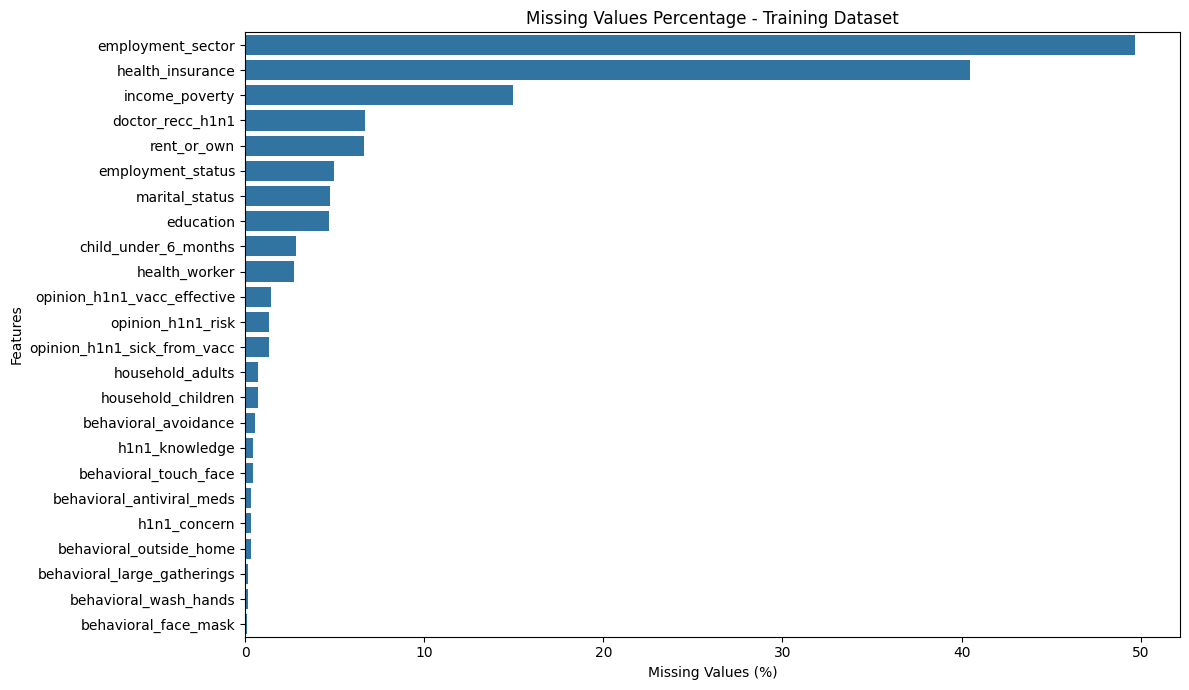

In [9]:
missing_percentage = (
    df_train.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage = missing_percentage[missing_percentage > 0]

plt.figure(figsize=(12, 7))

sns.barplot(
    x=missing_percentage.values,
    y=missing_percentage.index
)

plt.title("Missing Values Percentage - Training Dataset")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### 8. DUPLICATE RECORD ANALYSIS.

In [10]:
print("TRAINING DATASET")
print("=" * 40)

print("Duplicate rows:", df_train.duplicated().sum())

print(
    "Duplicate respondent IDs:",
    df_train['respondent_id'].duplicated().sum()
)

print("\nTESTING DATASET")
print("=" * 40)

print("Duplicate rows:", df_test.duplicated().sum())

print(
    "Duplicate respondent IDs:",
    df_test['respondent_id'].duplicated().sum()
)

# Check whether IDs overlap between datasets
overlapping_ids = set(df_train['respondent_id']).intersection(
    set(df_test['respondent_id'])
)

print("\nOverlapping respondent IDs:", len(overlapping_ids))

TRAINING DATASET
Duplicate rows: 0
Duplicate respondent IDs: 0

TESTING DATASET
Duplicate rows: 0
Duplicate respondent IDs: 0

Overlapping respondent IDs: 0


### 9. UNIQUE VALUE ANALYSIS

In [11]:
for column in df_train.columns:

    print("\n" + "=" * 60)
    print("FEATURE:", column)
    print("DATA TYPE:", df_train[column].dtype)
    print("UNIQUE VALUES:", df_train[column].nunique())
    print("SAMPLE VALUES:", df_train[column].dropna().unique()[:15])


FEATURE: respondent_id
DATA TYPE: int64
UNIQUE VALUES: 4756
SAMPLE VALUES: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]

FEATURE: h1n1_concern
DATA TYPE: float64
UNIQUE VALUES: 4
SAMPLE VALUES: [1. 2. 0. 3.]

FEATURE: h1n1_knowledge
DATA TYPE: float64
UNIQUE VALUES: 3
SAMPLE VALUES: [2. 1. 0.]

FEATURE: behavioral_antiviral_meds
DATA TYPE: float64
UNIQUE VALUES: 2
SAMPLE VALUES: [0. 1.]

FEATURE: behavioral_avoidance
DATA TYPE: float64
UNIQUE VALUES: 2
SAMPLE VALUES: [1. 0.]

FEATURE: behavioral_face_mask
DATA TYPE: float64
UNIQUE VALUES: 2
SAMPLE VALUES: [0. 1.]

FEATURE: behavioral_wash_hands
DATA TYPE: float64
UNIQUE VALUES: 2
SAMPLE VALUES: [1. 0.]

FEATURE: behavioral_large_gatherings
DATA TYPE: float64
UNIQUE VALUES: 2
SAMPLE VALUES: [0. 1.]

FEATURE: behavioral_outside_home
DATA TYPE: float64
UNIQUE VALUES: 2
SAMPLE VALUES: [0. 1.]

FEATURE: behavioral_touch_face
DATA TYPE: float64
UNIQUE VALUES: 2
SAMPLE VALUES: [1. 0.]

FEATURE: doctor_recc_h1n1
DATA TYPE: float64
UNIQUE VA

### 10. VACCINATION RATE BY FEATURE CATEGORY

In [13]:
# Exclude identifier and target
features = [
    col for col in df_train.columns
    if col not in ['respondent_id', 'h1n1_vaccine']
]

# Calculate vaccination rate for each feature category
vaccination_rates = {}

for feature in features:

    rates = (
        df_train.groupby(feature, observed=True)['h1n1_vaccine']
        .agg(['mean', 'count'])
        .reset_index()
    )

    rates['Vaccination_Rate_Percentage'] = rates['mean'] * 100

    vaccination_rates[feature] = rates

# Display selected important features
important_features = [
    'age_group',
    'doctor_recc_h1n1',
    'h1n1_concern',
    'h1n1_knowledge',
    'opinion_h1n1_vacc_effective',
    'opinion_h1n1_risk',
    'health_worker',
    'health_insurance',
    'sex'
]

for feature in important_features:

    print("\n" + "=" * 60)
    print(f"Vaccination rate by {feature}")

    display(
        vaccination_rates[feature][
            [feature, 'count', 'Vaccination_Rate_Percentage']
        ].round(2)
    )


Vaccination rate by age_group


,age_group,count,Vaccination_Rate_Percentage
0,18 - 34 Years,894,36.470
1,35 - 44 Years,659,39.610
2,45 - 54 Years,913,36.580
3,55 - 64 Years,1065,41.880
4,65+ Years,1225,41.390



Vaccination rate by doctor_recc_h1n1


,doctor_recc_h1n1,count,Vaccination_Rate_Percentage
0,0.000,3149,27.910
1,1.000,1288,72.750



Vaccination rate by h1n1_concern


,h1n1_concern,count,Vaccination_Rate_Percentage
0,0.000,522,29.500
1,1.000,1406,32.500
2,2.000,1980,42.070
3,3.000,833,50.900


... (8 outputs left out)


Vaccination rate by health_insurance


,health_insurance,count,Vaccination_Rate_Percentage
0,0.000,278,30.580
1,1.000,2553,52.290



Vaccination rate by sex


,sex,count,Vaccination_Rate_Percentage
0,Female,2921,40.670
1,Male,1835,37.380


### 11. VACCINATION RATE VISUALISATION

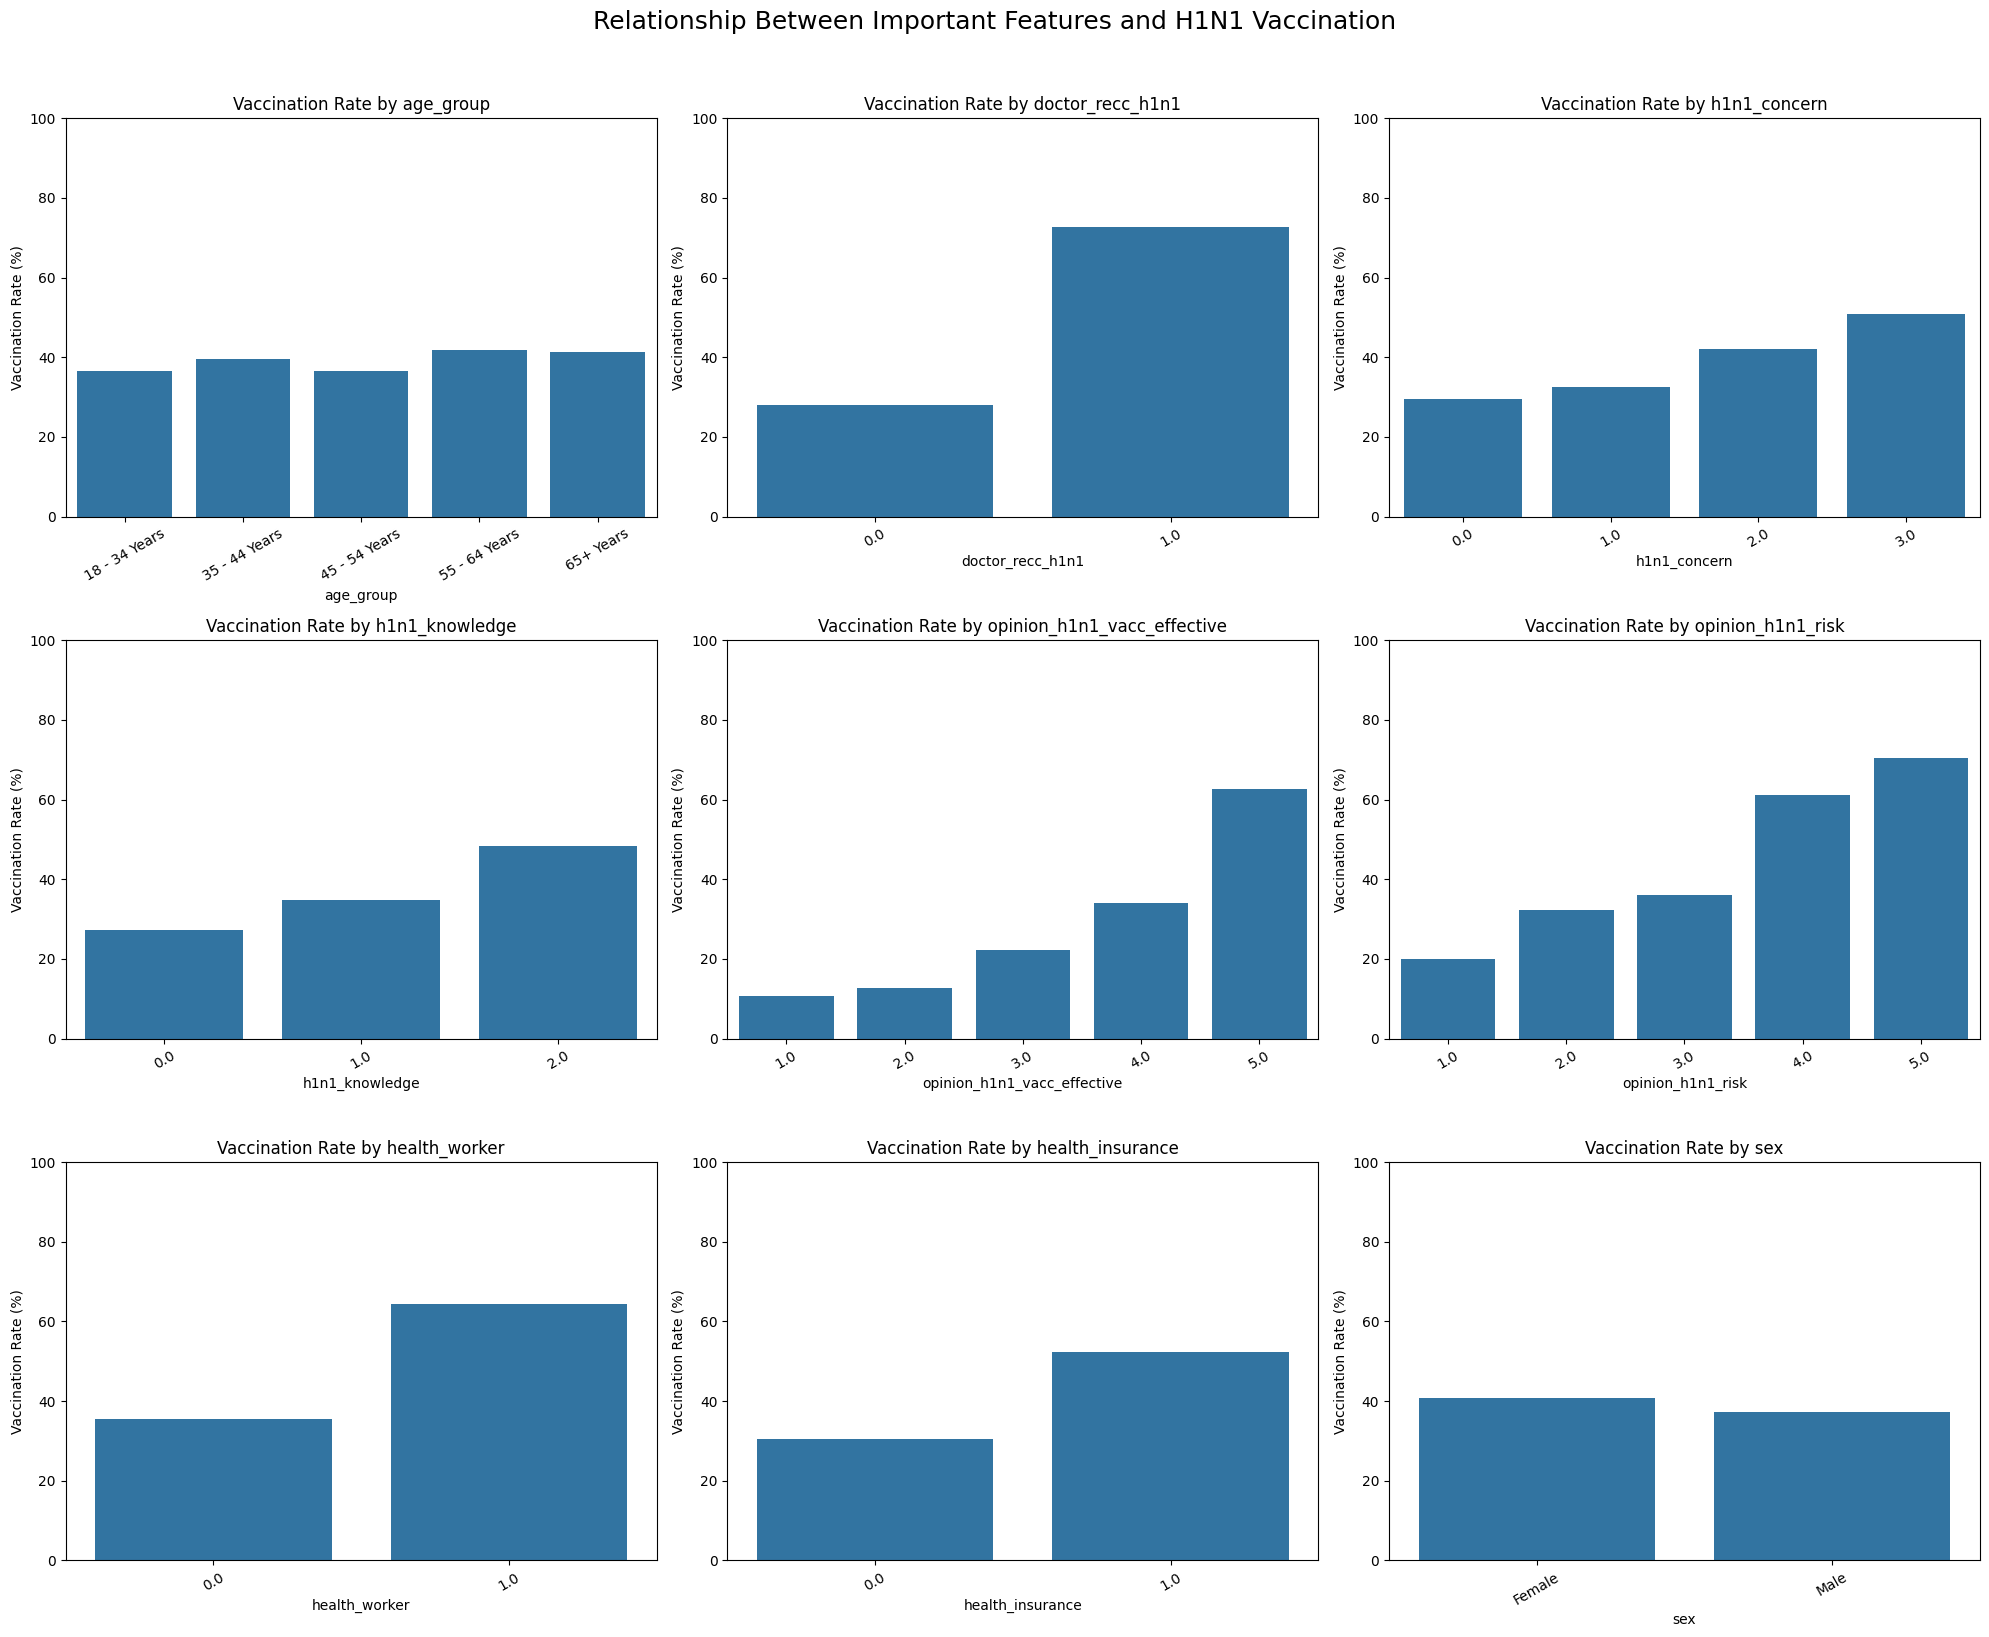

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(20, 16))

for ax, feature in zip(axes.flatten(), important_features):

    plot_data = (
        df_train.groupby(feature, observed=True)['h1n1_vaccine']
        .mean()
        .mul(100)
        .reset_index()
    )

    sns.barplot(
        data=plot_data,
        x=feature,
        y='h1n1_vaccine',
        ax=ax
    )

    ax.set_title(f'Vaccination Rate by {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Vaccination Rate (%)')

    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle(
    'Relationship Between Important Features and H1N1 Vaccination',
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()


### 12. EMPLOYMENT SECTOR MISSINGNESS ANALYSIS.

Employment status vs employment sector missingness


,Sector Available (%),Sector Missing (%)
employment_status,,
Employed,98.880,1.120
Not in Labor Force,0.000,100.000
Unemployed,0.000,100.000


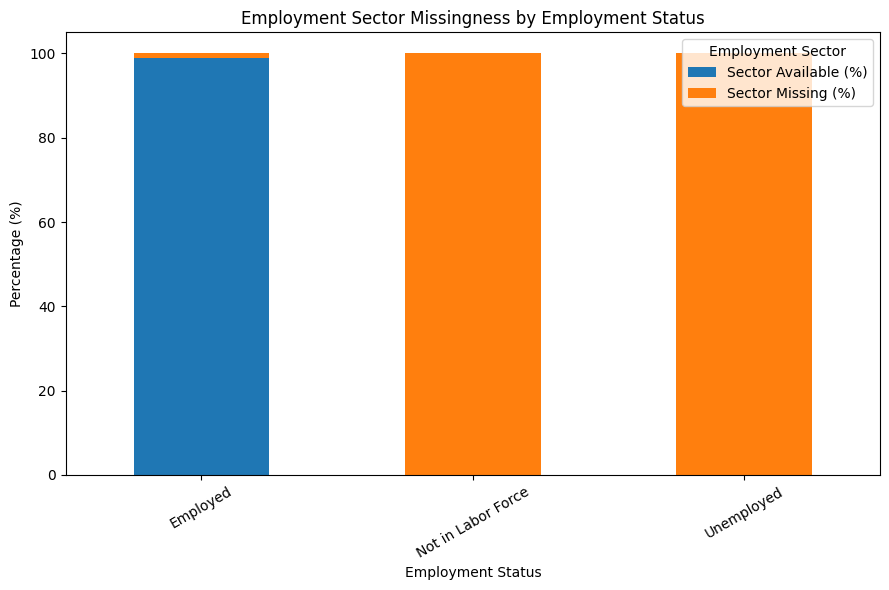

In [15]:
# Create a missingness indicator
df_train['employment_sector_missing'] = (
    df_train['employment_sector'].isnull()
)

# Cross-tabulation
employment_analysis = pd.crosstab(
    df_train['employment_status'],
    df_train['employment_sector_missing'],
    normalize='index'
) * 100

employment_analysis.columns = [
    'Sector Available (%)',
    'Sector Missing (%)'
]

print("Employment status vs employment sector missingness")
display(employment_analysis.round(2))

# Visualisation
employment_analysis.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 6)
)

plt.title('Employment Sector Missingness by Employment Status')
plt.ylabel('Percentage (%)')
plt.xlabel('Employment Status')
plt.xticks(rotation=30)
plt.legend(title='Employment Sector')
plt.tight_layout()
plt.show()


### 13. NUMERICAL FEATURE ANALYSIS

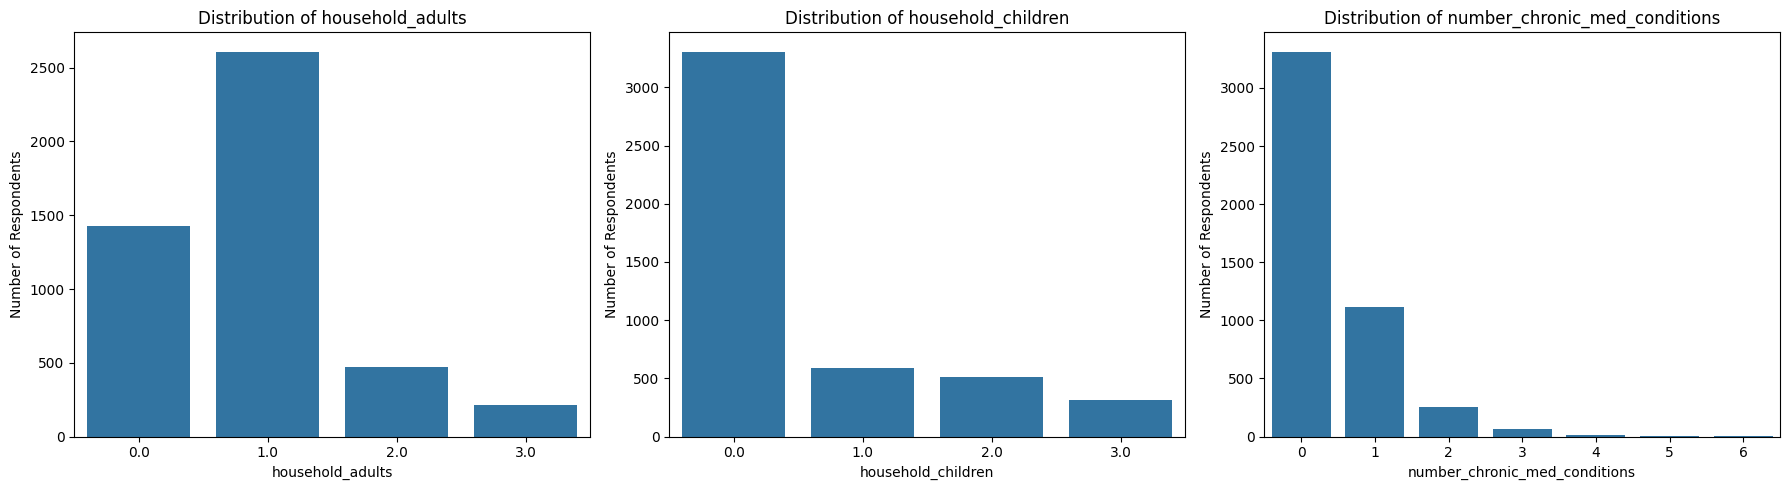

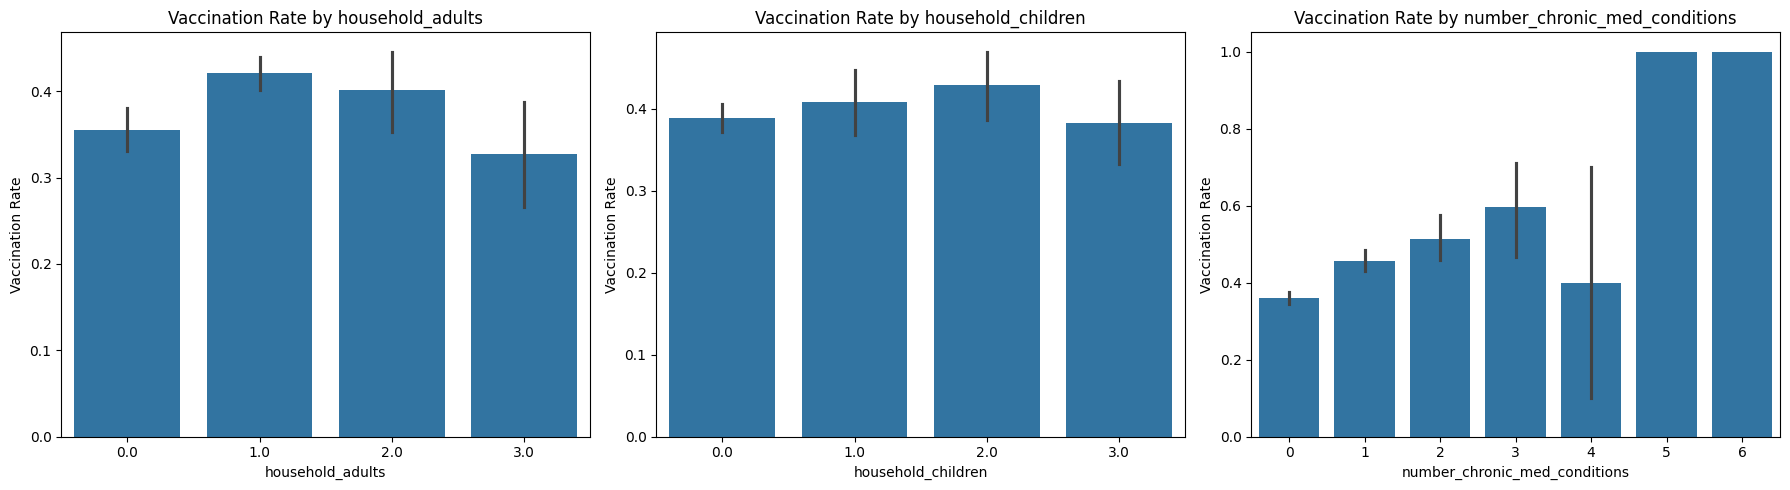

In [16]:


numerical_features = [
    'household_adults',
    'household_children',
    'number_chronic_med_conditions'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, numerical_features):

    sns.countplot(
        data=df_train,
        x=feature,
        ax=ax
    )

    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Number of Respondents')

plt.tight_layout()
plt.show()


# Vaccination rate across numerical/count features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, numerical_features):

    sns.barplot(
        data=df_train,
        x=feature,
        y='h1n1_vaccine',
        ax=ax
    )

    ax.set_title(f'Vaccination Rate by {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Vaccination Rate')

plt.tight_layout()
plt.show()


### 14. SEPARATE FEATURES AND TARGET

In [17]:

TARGET = 'h1n1_vaccine'
ID_COLUMN = 'respondent_id'

# Remove identifier and target from predictive features
X = df_train.drop(columns=[TARGET, ID_COLUMN])

# Target variable
y = df_train[TARGET]

# Keep test IDs separately for final submission
test_ids = df_test[ID_COLUMN].copy()

# Remove identifier from testing features
X_test = df_test.drop(columns=[ID_COLUMN])

print("Training features shape:", X.shape)
print("Target shape:", y.shape)
print("Testing features shape:", X_test.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))


Training features shape: (4756, 30)
Target shape: (4756,)
Testing features shape: (4749, 29)

Target distribution:
h1n1_vaccine
0   0.606
1   0.394
Name: proportion, dtype: float64


### 15. IDENTIFY FEATURE TYPES

In [18]:


categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical and ordinal features:")
print(numerical_features)

print("\nTotal predictive features:",
      len(categorical_features) + len(numerical_features))


Categorical features:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']

Numerical and ordinal features:
['h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'household_adults', 'household_children', 'number_chronic_med_conditions']

Total predictive features: 29


### 16. TRAIN-VALIDATION SPLIT

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training subset:", X_train.shape)
print("Validation subset:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))


Training subset: (3804, 30)
Validation subset: (952, 30)

Training target distribution:
h1n1_vaccine
0   0.606
1   0.394
Name: proportion, dtype: float64

Validation target distribution:
h1n1_vaccine
0   0.606
1   0.394
Name: proportion, dtype: float64


### 17. PREPROCESSING LIBRARIES

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


### 18. NUMERICAL PREPROCESSING

In [21]:
numerical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

### 19. CATEGORICAL PREPROCESSING

In [22]:
categorical_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(
            strategy='constant',
            fill_value='Missing'
        )),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore'
        ))
    ]
)

### 20. COMBINE PREPROCESSING

In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_pipeline, numerical_features),
        ('categorical', categorical_pipeline, categorical_features)
    ],
    remainder='drop'
)

print("Complete preprocessing pipeline created!")

Complete preprocessing pipeline created!


### 21. BASELINE MODEL

In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_val)

print("Baseline Accuracy:",
      accuracy_score(y_val, baseline_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    baseline_predictions,
    zero_division=0
))

Baseline Accuracy: 0.6060924369747899

Classification Report:
              precision    recall  f1-score   support

           0       0.61      1.00      0.75       577
           1       0.00      0.00      0.00       375

    accuracy                           0.61       952
   macro avg       0.30      0.50      0.38       952
weighted avg       0.37      0.61      0.46       952



### 22. MACHINE LEARNING ALGORITHMS

In [25]:
# Import algorithms and evaluation metrics



from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Machine learning algorithms imported!")


Machine learning algorithms imported!


### 23. DEFINE CLASSIFICATION MODELS

In [26]:
models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    'SVM': SVC(
        probability=True,
        random_state=42
    )
}

print("Total models:", len(models))


Total models: 7


### 24. TRAIN AND EVALUATE ALL MODELS

In [27]:
results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Complete pipeline
    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', model)
        ]
    )

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    predictions = pipeline.predict(X_val)

    # Predict probabilities for ROC-AUC
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Evaluate
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1 Score': f1_score(y_val, predictions),
        'ROC-AUC': roc_auc_score(y_val, probabilities)
    })

    trained_models[name] = pipeline

    print(f"{name} completed!")

# Create results dataframe
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")

display(results_df.round(4))



Training Logistic Regression...
Logistic Regression completed!

Training KNN...
KNN completed!

Training Decision Tree...
Decision Tree completed!

Training Random Forest...
Random Forest completed!

Training Extra Trees...
Extra Trees completed!

Training Gradient Boosting...
Gradient Boosting completed!

Training SVM...
SVM completed!

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.759,0.724,0.629,0.673,0.815
1,SVM,0.758,0.722,0.629,0.672,0.807
2,Gradient Boosting,0.762,0.728,0.629,0.675,0.806
3,Random Forest,0.752,0.717,0.613,0.661,0.797
4,Extra Trees,0.750,0.716,0.605,0.656,0.794
5,KNN,0.702,0.646,0.536,0.586,0.729
6,Decision Tree,0.653,0.556,0.595,0.575,0.643


### 25. MODEL PERFORMANCE VISUALISATION

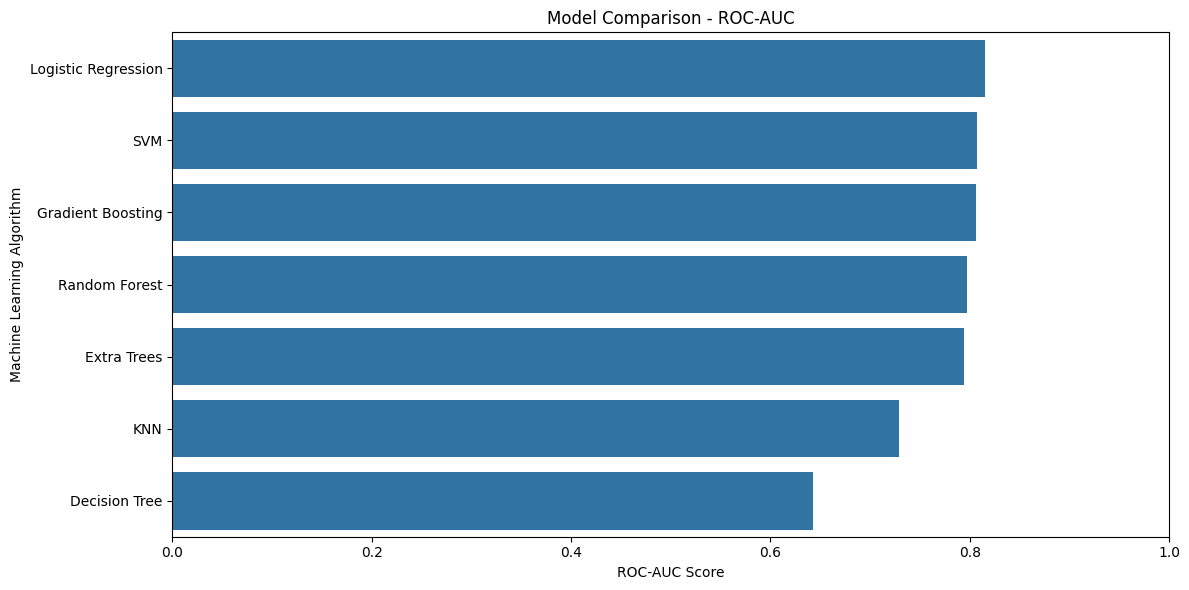

In [28]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='ROC-AUC',
    y='Model'
)

plt.title('Model Comparison - ROC-AUC')
plt.xlabel('ROC-AUC Score')
plt.ylabel('Machine Learning Algorithm')
plt.xlim(0, 1)

plt.tight_layout()
plt.show()


### 26. INSTALL ADVANCED ML LIBRARIES

In [29]:
!pip -q install xgboost lightgbm catboost

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

print("XGBoost, LightGBM and CatBoost imported successfully!")


XGBoost, LightGBM and CatBoost imported successfully!


### 27. DEFINE ADVANCED MODELS

In [30]:
advanced_models = {

    'XGBoost': XGBClassifier(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ),

    'LightGBM': LGBMClassifier(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=15,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    ),

    'CatBoost': CatBoostClassifier(
        iterations=500,
        learning_rate=0.03,
        depth=5,
        loss_function='Logloss',
        verbose=False,
        random_seed=42
    )
}

print("Advanced models defined:", len(advanced_models))


Advanced models defined: 3


### 28. TRAIN ADVANCED MODELS

In [31]:
advanced_results = []
advanced_trained_models = {}

for name, model in advanced_models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', model)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    advanced_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, predictions),
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1 Score': f1_score(y_val, predictions),
        'ROC-AUC': roc_auc_score(y_val, probabilities)
    })

    advanced_trained_models[name] = pipeline

    print(f"{name} completed!")

advanced_results_df = pd.DataFrame(advanced_results)

display(
    advanced_results_df.sort_values(
        by='ROC-AUC',
        ascending=False
    ).round(4)
)



Training XGBoost...
XGBoost completed!

Training LightGBM...
LightGBM completed!

Training CatBoost...
CatBoost completed!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.758,0.723,0.627,0.671,0.812
2,CatBoost,0.762,0.730,0.627,0.674,0.810
1,LightGBM,0.753,0.705,0.643,0.672,0.809


### 29. COMPLETE MODEL COMPARISON

In [32]:
all_results_df = pd.concat(
    [results_df, advanced_results_df],
    ignore_index=True
)

all_results_df = all_results_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

print("COMPLETE MODEL PERFORMANCE COMPARISON")

display(all_results_df.round(4))


COMPLETE MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.759,0.724,0.629,0.673,0.815
1,XGBoost,0.758,0.723,0.627,0.671,0.812
2,CatBoost,0.762,0.730,0.627,0.674,0.810
3,LightGBM,0.753,0.705,0.643,0.672,0.809
4,SVM,0.758,0.722,0.629,0.672,0.807
5,Gradient Boosting,0.762,0.728,0.629,0.675,0.806
6,Random Forest,0.752,0.717,0.613,0.661,0.797
7,Extra Trees,0.750,0.716,0.605,0.656,0.794
8,KNN,0.702,0.646,0.536,0.586,0.729
9,Decision Tree,0.653,0.556,0.595,0.575,0.643


### 30. ADVANCED MODEL COMPARISON

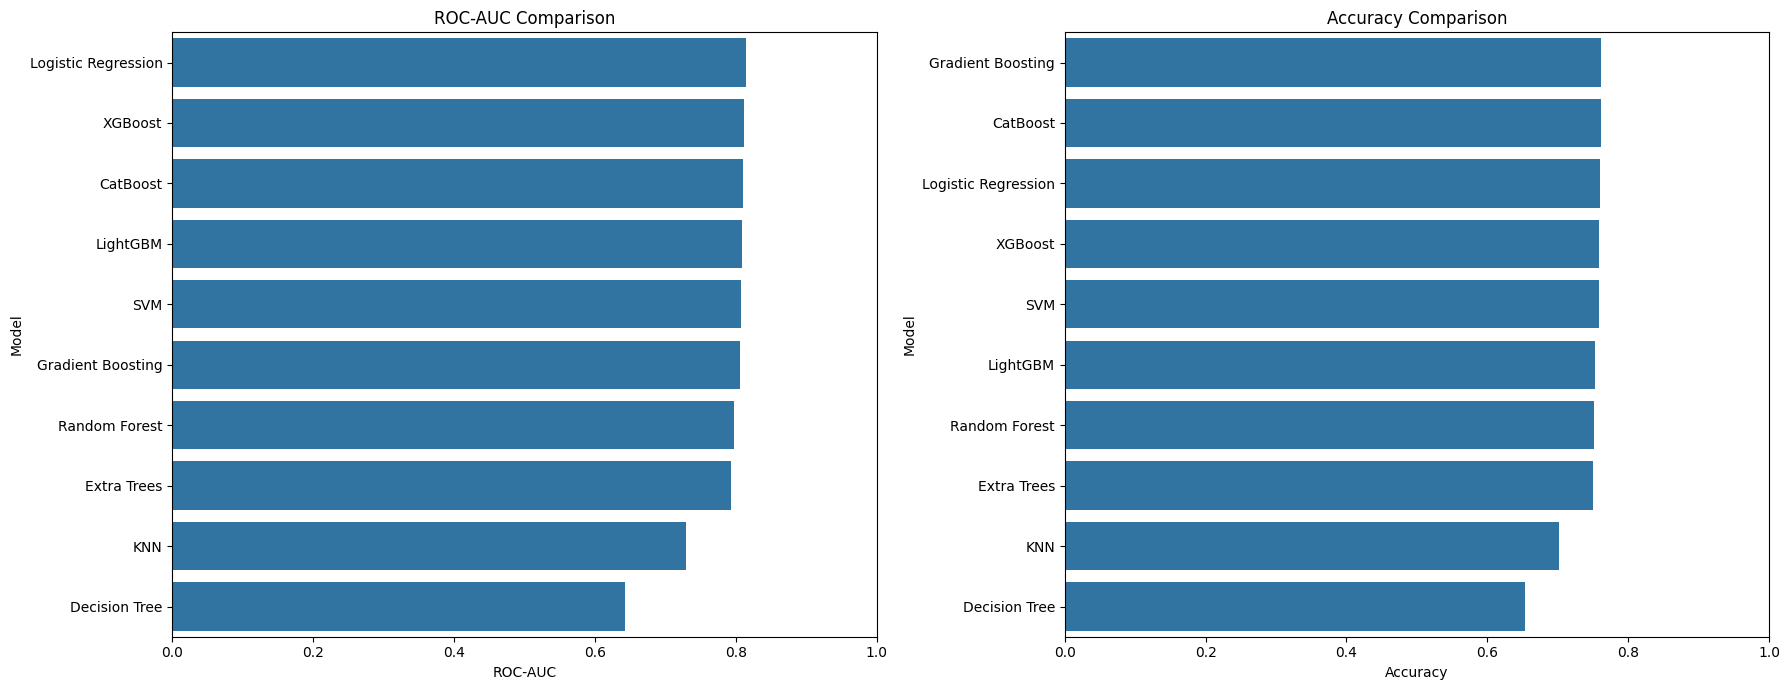

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ROC-AUC comparison
sns.barplot(
    data=all_results_df,
    x='ROC-AUC',
    y='Model',
    ax=axes[0]
)

axes[0].set_title('ROC-AUC Comparison')
axes[0].set_xlim(0, 1)

# Accuracy comparison
accuracy_sorted = all_results_df.sort_values(
    by='Accuracy',
    ascending=False
)

sns.barplot(
    data=accuracy_sorted,
    x='Accuracy',
    y='Model',
    ax=axes[1]
)

axes[1].set_title('Accuracy Comparison')
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()


### 31. HYPERPARAMETER OPTIMISATION LIBRARIES

In [34]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

from scipy.stats import randint, uniform, loguniform

print("Optimisation libraries imported successfully!")

Optimisation libraries imported successfully!


### 32. STRATIFIED CROSS-VALIDATION

In [35]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation configured.")

5-Fold Stratified Cross-Validation configured.


### 33. DEFINE HYPERPARAMETER SEARCH SPACES

In [36]:

param_distributions = {

    'Logistic Regression': {
        'classifier__C': loguniform(0.001, 100),
        'classifier__solver': ['lbfgs'],
        'classifier__max_iter': [2000, 3000, 5000]
    },

    'XGBoost': {
        'classifier__n_estimators': randint(200, 800),
        'classifier__max_depth': randint(2, 7),
        'classifier__learning_rate': loguniform(0.01, 0.15),
        'classifier__subsample': uniform(0.65, 0.35),
        'classifier__colsample_bytree': uniform(0.65, 0.35),
        'classifier__min_child_weight': randint(1, 8),
        'classifier__reg_lambda': loguniform(0.1, 10)
    },

    'CatBoost': {
        'classifier__iterations': randint(250, 800),
        'classifier__depth': randint(4, 9),
        'classifier__learning_rate': loguniform(0.01, 0.15),
        'classifier__l2_leaf_reg': uniform(1, 9)
    },

    'LightGBM': {
        'classifier__n_estimators': randint(200, 800),
        'classifier__num_leaves': randint(8, 40),
        'classifier__learning_rate': loguniform(0.01, 0.15),
        'classifier__max_depth': [-1, 3, 5, 7],
        'classifier__min_child_samples': randint(10, 50),
        'classifier__reg_lambda': loguniform(0.1, 10)
    },

    'Gradient Boosting': {
        'classifier__n_estimators': randint(100, 500),
        'classifier__learning_rate': loguniform(0.01, 0.15),
        'classifier__max_depth': randint(1, 5),
        'classifier__min_samples_split': randint(2, 15),
        'classifier__min_samples_leaf': randint(1, 10),
        'classifier__subsample': uniform(0.65, 0.35)
    }
}

print("Hyperparameter search spaces created!")


Hyperparameter search spaces created!


### 34. MODELS FOR HYPERPARAMETER TUNING

In [37]:

tuning_models = {
    'Logistic Regression': LogisticRegression(random_state=42),

    'XGBoost': XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=1
    ),

    'CatBoost': CatBoostClassifier(
        loss_function='Logloss',
        verbose=False,
        random_seed=42,
        thread_count=1
    ),

    'LightGBM': LGBMClassifier(
        verbosity=-1,
        random_state=42,
        n_jobs=1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )
}

print("Five models ready for optimisation.")


Five models ready for optimisation.


### 35. RANDOMIZED SEARCH CROSS-VALIDATION

In [38]:

tuned_models = {}
tuning_results = []

for name, model in tuning_models.items():

    print("\n" + "=" * 60)
    print(f"Optimising: {name}")
    print("=" * 60)

    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', model)
        ]
    )

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[name],
        n_iter=15,
        scoring='roc_auc',
        cv=cv_strategy,
        random_state=42,
        n_jobs=1,
        verbose=1,
        refit=True
    )

    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        'Model': name,
        'Best_CV_ROC_AUC': search.best_score_,
        'Best_Parameters': search.best_params_
    })

    print(f"\nBest CV ROC-AUC: {search.best_score_:.4f}")
    print("Best parameters:")
    print(search.best_params_)

tuning_results_df = pd.DataFrame(tuning_results)

print("\nHYPERPARAMETER OPTIMISATION RESULTS")

display(
    tuning_results_df[
        ['Model', 'Best_CV_ROC_AUC']
    ].sort_values(
        by='Best_CV_ROC_AUC',
        ascending=False
    ).round(4)
)



Optimising: Logistic Regression
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best CV ROC-AUC: 0.8233
Best parameters:
{'classifier__C': np.float64(0.09984006580328653), 'classifier__max_iter': 5000, 'classifier__solver': 'lbfgs'}

Optimising: XGBoost
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best CV ROC-AUC: 0.8348
Best parameters:
{'classifier__colsample_bytree': np.float64(0.9726559822580909), 'classifier__learning_rate': np.float64(0.012707942999213693), 'classifier__max_depth': 5, 'classifier__min_child_weight': 1, 'classifier__n_estimators': 495, 'classifier__reg_lambda': np.float64(4.887285358835578), 'classifier__subsample': np.float64(0.9115620385480834)}

Optimising: CatBoost
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best CV ROC-AUC: 0.8367
Best parameters:
{'classifier__depth': 8, 'classifier__iterations': 593, 'classifier__l2_leaf_reg': np.float64(8.491983767203795), 'classifier__learning_rate': np.float64(0.017771749

,Model,Best_CV_ROC_AUC
2,CatBoost,0.837
1,XGBoost,0.835
4,Gradient Boosting,0.833
3,LightGBM,0.832
0,Logistic Regression,0.823


### 36. EVALUATE TUNED MODELS

In [39]:

tuned_validation_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_val)

    probabilities = model.predict_proba(X_val)[:, 1]

    tuned_validation_results.append({

        'Model': name,

        'Accuracy': accuracy_score(
            y_val, predictions
        ),

        'Precision': precision_score(
            y_val, predictions
        ),

        'Recall': recall_score(
            y_val, predictions
        ),

        'F1 Score': f1_score(
            y_val, predictions
        ),

        'ROC-AUC': roc_auc_score(
            y_val, probabilities
        )
    })

tuned_validation_df = pd.DataFrame(
    tuned_validation_results
)

tuned_validation_df = tuned_validation_df.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

print("TUNED MODEL VALIDATION PERFORMANCE")

display(tuned_validation_df.round(4))


TUNED MODEL VALIDATION PERFORMANCE


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.758,0.725,0.624,0.670,0.815
1,Gradient Boosting,0.766,0.739,0.627,0.678,0.812
2,CatBoost,0.757,0.721,0.627,0.670,0.808
3,XGBoost,0.748,0.708,0.613,0.657,0.808
4,LightGBM,0.751,0.718,0.605,0.657,0.805


### 37. ORIGINAL VS TUNED MODELS

In [40]:
original_selected = all_results_df[
    all_results_df['Model'].isin(tuning_models.keys())
].copy()

original_selected = original_selected[
    ['Model', 'Accuracy', 'ROC-AUC']
]

tuned_selected = tuned_validation_df[
    ['Model', 'Accuracy', 'ROC-AUC']
]

comparison = original_selected.merge(
    tuned_selected,
    on='Model',
    suffixes=('_Original', '_Tuned')
)

comparison['ROC_AUC_Improvement'] = (
    comparison['ROC-AUC_Tuned'] -
    comparison['ROC-AUC_Original']
)

comparison['Accuracy_Improvement'] = (
    comparison['Accuracy_Tuned'] -
    comparison['Accuracy_Original']
)

display(comparison.round(4))


,Model,Accuracy_Original,ROC-AUC_Original,Accuracy_Tuned,ROC-AUC_Tuned,ROC_AUC_Improvement,Accuracy_Improvement
0,Logistic Regression,0.759,0.815,0.758,0.815,-0.000,-0.001
1,XGBoost,0.758,0.812,0.748,0.808,-0.005,-0.011
2,CatBoost,0.762,0.810,0.757,0.808,-0.002,-0.004
3,LightGBM,0.753,0.809,0.751,0.805,-0.004,-0.002
4,Gradient Boosting,0.762,0.806,0.766,0.812,0.006,0.004


Logistic Regression: It remains our strongest model according to ROC-AUC. Its performance is stable even after optimisation.

Gradient Boosting: This is particularly interesting. Its accuracy increased from 76.2% to 76.6%, while ROC-AUC increased from 0.806 to 0.812.

XGBoost, CatBoost and LightGBM: Their tuned versions performed slightly worse on our validation dataset. We shouldn't automatically prefer tuned models over their original versions.

Our next objective is to understand how these models make predictions, not just compare their scores.

###  38. SELECT TOP THREE CANDIDATES

In [41]:
candidate_models = {
    'Logistic Regression': trained_models['Logistic Regression'],
    'Tuned Gradient Boosting': tuned_models['Gradient Boosting'],
    'Original XGBoost': advanced_trained_models['XGBoost']
}

print("Selected models for diagnostic evaluation:")

for name in candidate_models:
    print("-", name)


Selected models for diagnostic evaluation:
- Logistic Regression
- Tuned Gradient Boosting
- Original XGBoost


### 39. CONFUSION MATRIX COMPARISON

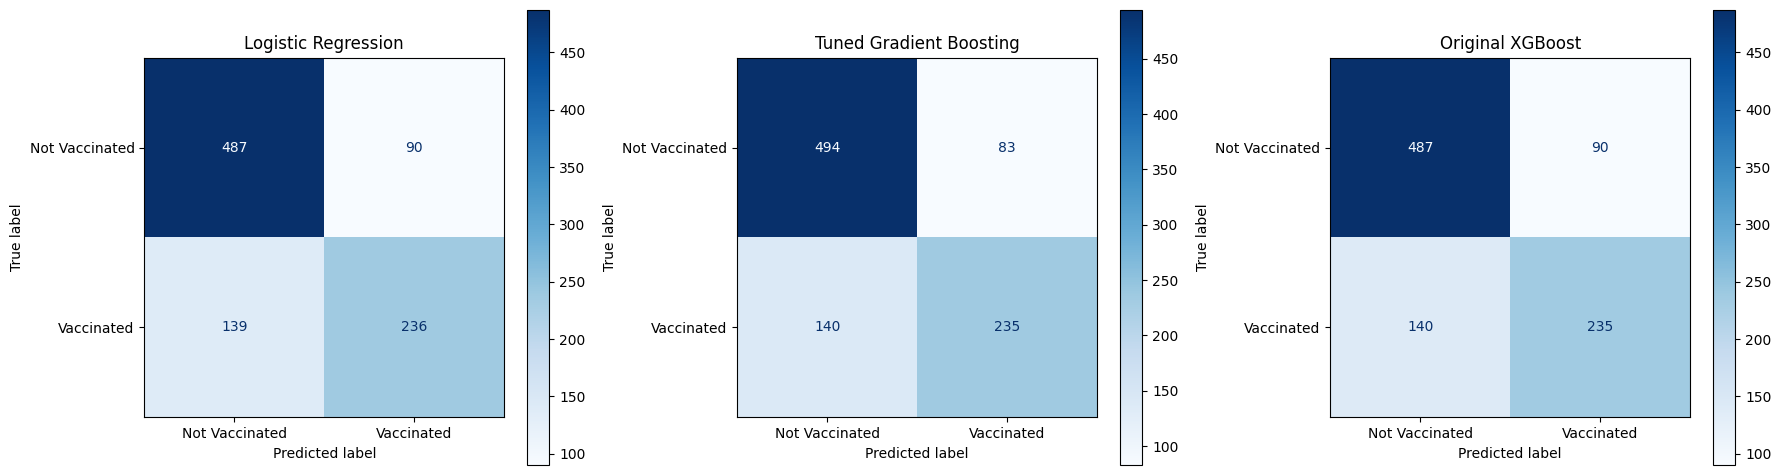

In [42]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(
    axes,
    candidate_models.items()
):

    predictions = model.predict(X_val)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        display_labels=['Not Vaccinated', 'Vaccinated'],
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


### 40. ROC CURVE COMPARISON

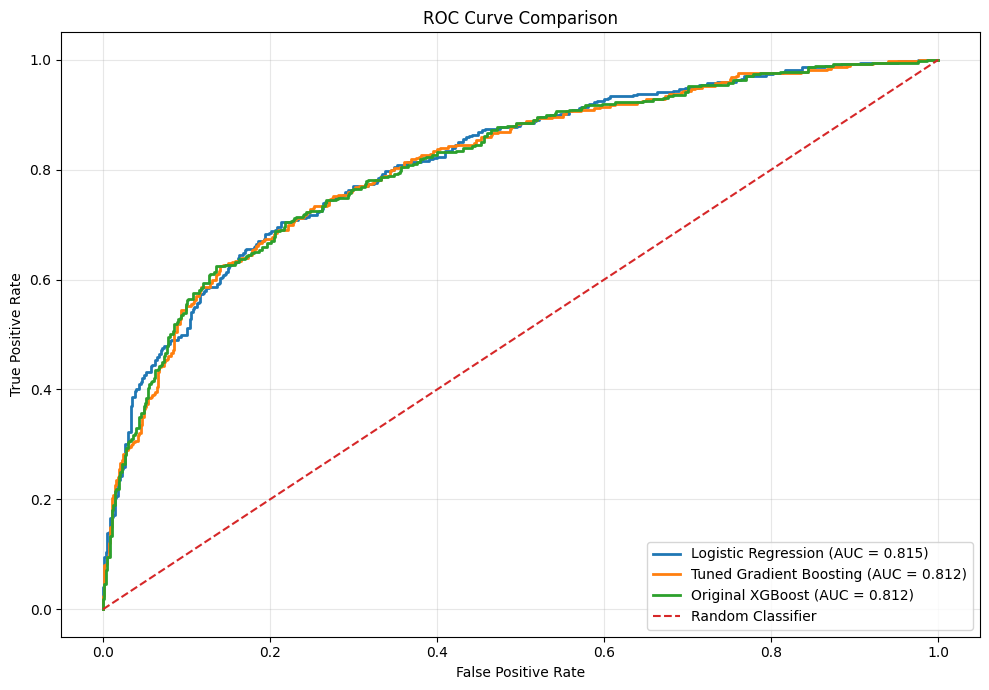

In [43]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

for name, model in candidate_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_val,
        probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {roc_auc:.3f})'
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 41. DETAILED CLASSIFICATION REPORTS

In [44]:
from sklearn.metrics import classification_report

for name, model in candidate_models.items():

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    predictions = model.predict(X_val)

    print(
        classification_report(
            y_val,
            predictions,
            target_names=[
                'Not Vaccinated (0)',
                'Vaccinated (1)'
            ],
            digits=4
        )
    )



Logistic Regression
                    precision    recall  f1-score   support

Not Vaccinated (0)     0.7780    0.8440    0.8096       577
    Vaccinated (1)     0.7239    0.6293    0.6733       375

          accuracy                         0.7595       952
         macro avg     0.7509    0.7367    0.7415       952
      weighted avg     0.7567    0.7595    0.7559       952


Tuned Gradient Boosting
                    precision    recall  f1-score   support

Not Vaccinated (0)     0.7792    0.8562    0.8159       577
    Vaccinated (1)     0.7390    0.6267    0.6782       375

          accuracy                         0.7658       952
         macro avg     0.7591    0.7414    0.7470       952
      weighted avg     0.7634    0.7658    0.7616       952


Original XGBoost
                    precision    recall  f1-score   support

Not Vaccinated (0)     0.7767    0.8440    0.8090       577
    Vaccinated (1)     0.7231    0.6267    0.6714       375

          accuracy          

###  42. PERMUTATION IMPORTANCE

In [45]:
from sklearn.inspection import permutation_importance

print("Permutation importance imported successfully!")

Permutation importance imported successfully!


###  43. CALCULATE PERMUTATION IMPORTANCE

In [46]:
permutation_results = {}

for name, model in candidate_models.items():

    print(f"\nCalculating feature importance: {name}")

    importance = permutation_importance(
        model,
        X_val,
        y_val,
        scoring='roc_auc',
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        'Feature': X_val.columns,
        'Importance_Mean': importance.importances_mean,
        'Importance_Std': importance.importances_std
    })

    importance_df = importance_df.sort_values(
        by='Importance_Mean',
        ascending=False
    ).reset_index(drop=True)

    permutation_results[name] = importance_df

    print(f"\nTop 15 features for {name}:")

    display(importance_df.head(15).round(4))



Calculating feature importance: Logistic Regression

Top 15 features for Logistic Regression:


,Feature,Importance_Mean,Importance_Std
0,doctor_recc_h1n1,0.095,0.008
1,opinion_h1n1_vacc_effective,0.053,0.006
2,employment_sector,0.034,0.004
3,opinion_h1n1_risk,0.032,0.007
4,employment_status,0.018,0.004
5,health_worker,0.009,0.002
6,education,0.006,0.002
7,race,0.004,0.002
8,age_group,0.004,0.001
9,sex,0.003,0.001



Calculating feature importance: Tuned Gradient Boosting

Top 15 features for Tuned Gradient Boosting:


,Feature,Importance_Mean,Importance_Std
0,doctor_recc_h1n1,0.098,0.007
1,opinion_h1n1_vacc_effective,0.052,0.009
2,opinion_h1n1_risk,0.034,0.009
3,health_worker,0.009,0.002
4,employment_sector,0.005,0.002
5,education,0.004,0.001
6,race,0.003,0.002
7,age_group,0.003,0.002
8,opinion_h1n1_sick_from_vacc,0.002,0.001
9,h1n1_knowledge,0.001,0.001



Calculating feature importance: Original XGBoost

Top 15 features for Original XGBoost:


,Feature,Importance_Mean,Importance_Std
0,doctor_recc_h1n1,0.097,0.008
1,opinion_h1n1_vacc_effective,0.053,0.009
2,opinion_h1n1_risk,0.033,0.008
3,health_worker,0.009,0.002
4,age_group,0.004,0.001
5,employment_sector,0.004,0.002
6,education,0.004,0.001
7,race,0.003,0.002
8,opinion_h1n1_sick_from_vacc,0.003,0.002
9,behavioral_large_gatherings,0.002,0.002


### 44. FEATURE IMPORTANCE VISUALISATION

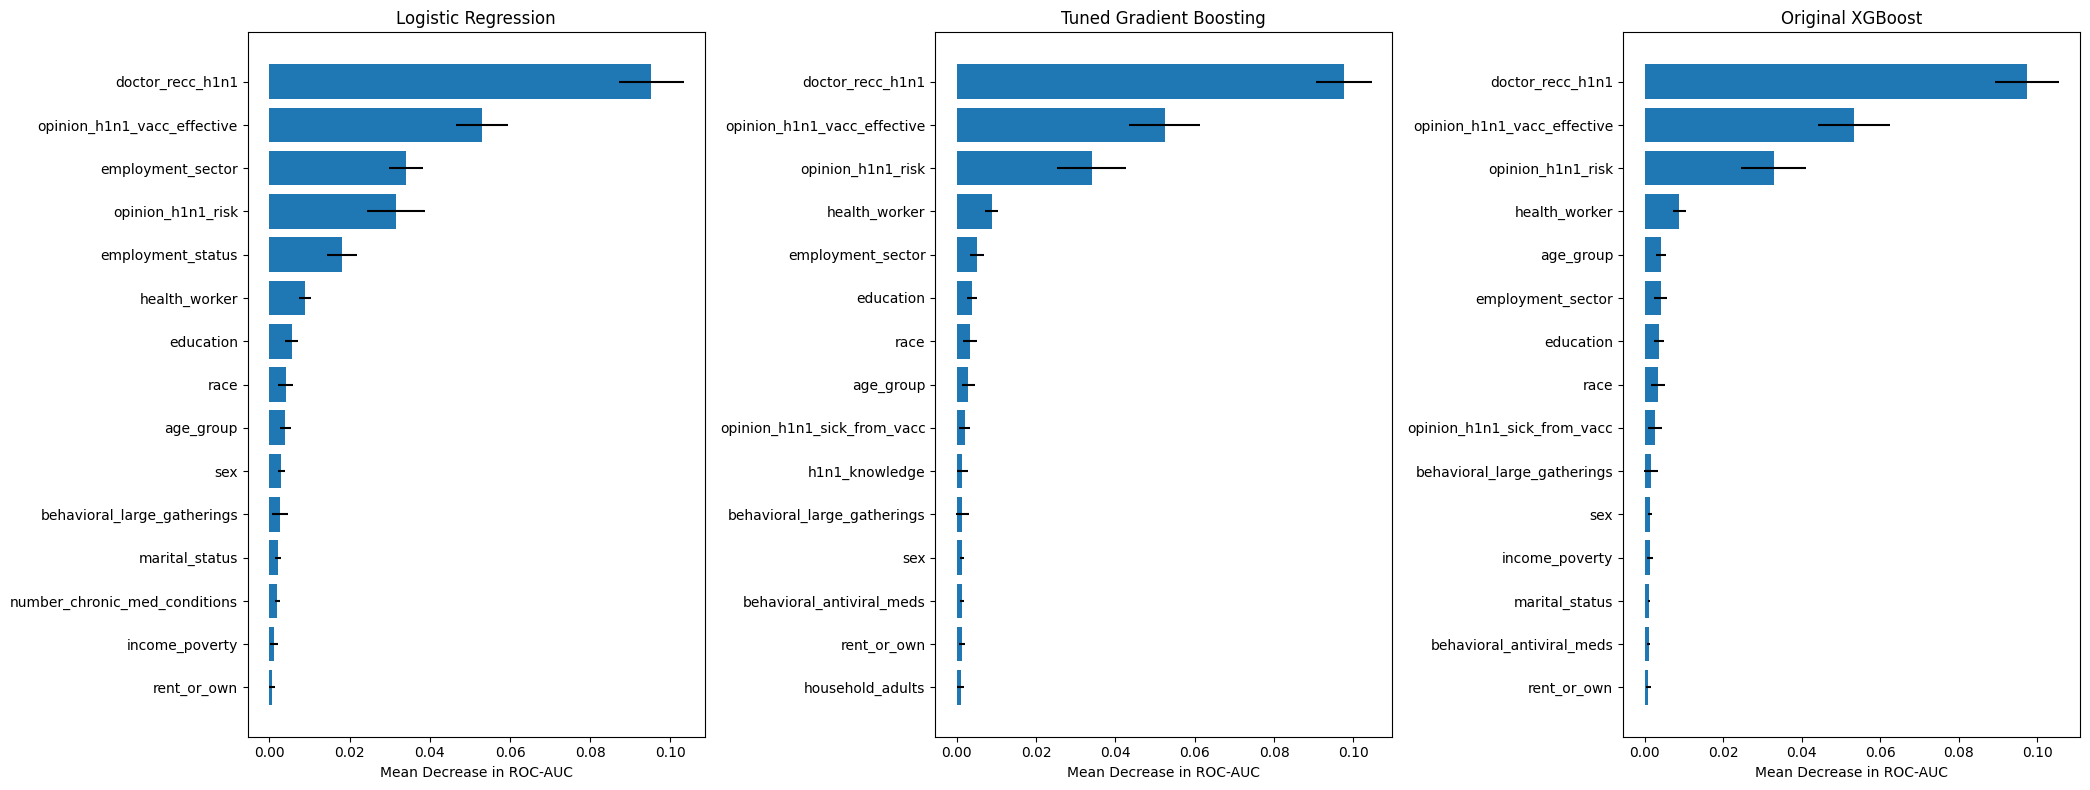

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(21, 8))

for ax, (name, importance_df) in zip(
    axes,
    permutation_results.items()
):

    top_features = importance_df.head(15).sort_values(
        by='Importance_Mean',
        ascending=True
    )

    ax.barh(
        top_features['Feature'],
        top_features['Importance_Mean'],
        xerr=top_features['Importance_Std']
    )

    ax.set_title(name)
    ax.set_xlabel('Mean Decrease in ROC-AUC')

plt.tight_layout()
plt.show()


### 45. CROSS-MODEL FEATURE IMPORTANCE

In [48]:
importance_comparison = pd.DataFrame({
    name: df.set_index('Feature')['Importance_Mean']
    for name, df in permutation_results.items()
})

importance_comparison['Average_Importance'] = (
    importance_comparison.mean(axis=1)
)

importance_comparison = importance_comparison.sort_values(
    by='Average_Importance',
    ascending=False
)

display(importance_comparison.head(20).round(4))


,Logistic Regression,Tuned Gradient Boosting,Original XGBoost,Average_Importance
Feature,,,,
doctor_recc_h1n1,0.095,0.098,0.097,0.097
opinion_h1n1_vacc_effective,0.053,0.052,0.053,0.053
opinion_h1n1_risk,0.032,0.034,0.033,0.033
employment_sector,0.034,0.005,0.004,0.014
health_worker,0.009,0.009,0.009,0.009
employment_status,0.018,0.000,-0.001,0.006
education,0.006,0.004,0.004,0.004
age_group,0.004,0.003,0.004,0.004
race,0.004,0.003,0.003,0.004


### 47. GET PREDICTED PROBABILITIES

In [49]:

candidate_models = {
    'Logistic Regression': trained_models['Logistic Regression'],
    'Tuned Gradient Boosting': tuned_models['Gradient Boosting'],
    'Original XGBoost': advanced_trained_models['XGBoost']
}

validation_probabilities = {}

for name, model in candidate_models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    validation_probabilities[name] = probabilities

print("Validation probabilities generated.")

Validation probabilities generated.


### 48. THRESHOLD COMPARISON

In [50]:
# ============================================
#
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

threshold_results = []

for name, probabilities in validation_probabilities.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'Accuracy': accuracy_score(y_val, predictions),
            'Precision': precision_score(y_val, predictions, zero_division=0),
            'Recall': recall_score(y_val, predictions, zero_division=0),
            'F1_Score': f1_score(y_val, predictions, zero_division=0)
        })

threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df
    .sort_values(['Model', 'Threshold'])
    .round(3)
)

,Model,Threshold,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.300,0.711,0.600,0.800,0.686
1,Logistic Regression,0.350,0.728,0.627,0.763,0.688
2,Logistic Regression,0.400,0.739,0.655,0.715,0.684
3,Logistic Regression,0.450,0.753,0.693,0.669,0.681
4,Logistic Regression,0.500,0.759,0.724,0.629,0.673
5,Logistic Regression,0.550,0.759,0.748,0.587,0.658
6,Logistic Regression,0.600,0.755,0.767,0.544,0.637
7,Logistic Regression,0.650,0.748,0.800,0.480,0.600
8,Logistic Regression,0.700,0.742,0.831,0.432,0.568
18,Original XGBoost,0.300,0.712,0.604,0.781,0.681


### 49. BEST F1 THRESHOLD

In [51]:
best_thresholds = (
    threshold_results_df
    .loc[
        threshold_results_df.groupby('Model')['F1_Score'].idxmax()
    ]
    .sort_values('F1_Score', ascending=False)
    .reset_index(drop=True)
)

display(best_thresholds.round(3))

,Model,Threshold,Accuracy,Precision,Recall,F1_Score
0,Tuned Gradient Boosting,0.350,0.732,0.635,0.752,0.689
1,Logistic Regression,0.350,0.728,0.627,0.763,0.688
2,Original XGBoost,0.400,0.743,0.659,0.717,0.687


### 50. FINAL MODEL SELECTION

In [52]:
final_model = tuned_models['Gradient Boosting']
FINAL_THRESHOLD = 0.35

print("Selected model: Tuned Gradient Boosting")
print("Selected threshold:", FINAL_THRESHOLD)

Selected model: Tuned Gradient Boosting
Selected threshold: 0.35


### 51. TRAIN FINAL MODEL

In [53]:
final_model.fit(X, y)

print("Final model trained successfully.")
print("Training records used:", len(X))
print("Features used:", X.shape[1])

Final model trained successfully.
Training records used: 4756
Features used: 30


### 52. GENERATE TEST PREDICTIONS

In [54]:
test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

print("Predictions generated successfully.")
print("Total predictions:", len(test_predictions))

Predictions generated successfully.
Total predictions: 4749


### 53. CREATE SUBMISSION FILE

In [55]:
submission = pd.DataFrame({
    'respondent_id': test_ids,
    'h1n1_vaccine': test_predictions
})

submission.to_csv(
    '/content/h1n1_vaccine_predictions.csv',
    index=False
)

display(submission.head(10))

,respondent_id,h1n1_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,1
7,4764,1
8,4765,1
9,4766,1


### 54. SUBMISSION VALIDATION

In [56]:
print("Submission shape:", submission.shape)

print("\nColumn names:")
print(submission.columns.tolist())

print("\nMissing values:")
print(submission.isnull().sum())

print("\nPrediction distribution:")
print(submission['h1n1_vaccine'].value_counts())

print("\nUnique prediction values:")
print(submission['h1n1_vaccine'].unique())

assert submission.shape == (len(df_test), 2)
assert submission.columns.tolist() == [
    'respondent_id',
    'h1n1_vaccine'
]
assert submission.isnull().sum().sum() == 0
assert set(submission['h1n1_vaccine'].unique()).issubset({0, 1})
assert submission['respondent_id'].equals(test_ids.reset_index(drop=True))

print("\nAll submission checks passed!")

Submission shape: (4749, 2)

Column names:
['respondent_id', 'h1n1_vaccine']

Missing values:
respondent_id    0
h1n1_vaccine     0
dtype: int64

Prediction distribution:
h1n1_vaccine
0    2548
1    2201
Name: count, dtype: int64

Unique prediction values:
[0 1]

All submission checks passed!


In [57]:
from google.colab import files

files.download('/content/h1n1_vaccine_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>